# Comprendre la volatilité réalisée à cinq séances

**Question scientifique :** quel est le comportement historique de la série construite dans le notebook 01, où se situent ses observations extrêmes, quelle persistance présente-t-elle et quelles sont ses limites comme mesure du risque ?

Cette étape est strictement descriptive. Elle n'introduit ni modèle prédictif, ni découpage économique, ni variable supplémentaire.

## 1. Reproduction de la série auditée

Le notebook recharge la source officielle et reproduit exactement la convention validée : rendement total du marché égal à `Mkt-RF + RF`, conversion du pourcentage au décimal, puis racine de la moyenne annualisée des cinq rendements futurs au carré.

In [1]:
from datetime import datetime, timezone
from hashlib import sha256
from io import BytesIO, StringIO
from urllib.request import urlopen
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

SOURCE_URL = (
    'https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/'
    'F-F_Research_Data_Factors_daily_CSV.zip'
)
HORIZON = 5
ANNUALIZATION_DAYS = 252
plt.style.use('seaborn-v0_8-whitegrid')
print(f'pandas={pd.__version__}; numpy={np.__version__}')

pandas=2.2.3; numpy=2.2.1


In [2]:
downloaded_at_utc = datetime.now(timezone.utc).isoformat()
with urlopen(SOURCE_URL, timeout=60) as response:
    archive_bytes = response.read()
archive_sha256 = sha256(archive_bytes).hexdigest()

with ZipFile(BytesIO(archive_bytes)) as archive:
    member_name = archive.namelist()[0]
    text = archive.read(member_name).decode('utf-8-sig')
lines = text.splitlines()
header_index = next(i for i, line in enumerate(lines) if line.strip().startswith(',Mkt-RF'))
data_lines = [lines[header_index]]
for line in lines[header_index + 1:]:
    first_field = line.split(',', 1)[0].strip()
    if len(first_field) == 8 and first_field.isdigit():
        data_lines.append(line)
    else:
        break

factors = pd.read_csv(StringIO('\n'.join(data_lines)))
factors = factors.rename(columns={factors.columns[0]: 'date'})
factors['date'] = pd.to_datetime(factors['date'].astype(str), format='%Y%m%d', errors='raise')
factors = factors.set_index('date')
market_return = (factors['Mkt-RF'] + factors['RF']) / 100.0
future_returns = pd.concat(
    {f'r_t_plus_{k}': market_return.shift(-k) for k in range(1, HORIZON + 1)},
    axis=1,
)
rv_5 = np.sqrt(
    (ANNUALIZATION_DAYS / HORIZON)
    * future_returns.pow(2).sum(axis=1, min_count=HORIZON)
).dropna()
rv_5_pct = 100 * rv_5

assert len(rv_5) == len(factors) - HORIZON
assert rv_5.index.is_monotonic_increasing and not rv_5.index.has_duplicates
print(f'Millésime : {lines[0]}')
print(f'Téléchargé à : {downloaded_at_utc}')
print(f'SHA-256 : {archive_sha256}')
print(f'Série analysée : {rv_5.index.min().date()} → {rv_5.index.max().date()} ({len(rv_5):,} observations)')

Millésime : This file was created by using the 202608 CRSP database.
Téléchargé à : 2026-10-15T00:19:40.039429+00:00
SHA-256 : 2f29e22546069914890a712680a6f81f3680ebc3543b52864484d209ca13a7db
Série analysée : 1926-07-01 → 2026-08-24 (26,312 observations)


## 2. Niveau et dispersion

La moyenne est sensible aux épisodes extrêmes. Les quantiles décrivent donc mieux une distribution très dissymétrique. Toutes les valeurs affichées ci-dessous sont des volatilités annualisées en pourcentage.

In [3]:
summary = pd.Series({
    'minimum': rv_5_pct.min(),
    'q01': rv_5_pct.quantile(0.01),
    'q05': rv_5_pct.quantile(0.05),
    'médiane': rv_5_pct.median(),
    'moyenne': rv_5_pct.mean(),
    'q95': rv_5_pct.quantile(0.95),
    'q99': rv_5_pct.quantile(0.99),
    'maximum': rv_5_pct.max(),
}, name='volatilité annualisée (%)')
print(summary.round(3).to_string())
print(f'Asymétrie empirique : {rv_5_pct.skew():.3f}')

minimum      0.819
q01          2.677
q05          4.172
médiane     10.609
moyenne     13.444
q95         32.027
q99         55.742
maximum    148.600
Asymétrie empirique : 3.611


## 3. Comportement historique

Le premier graphique conserve la fréquence quotidienne et rend visibles les pointes. Le second résume chaque année par sa médiane et son 95e centile ; il facilite la lecture de longue période, mais masque nécessairement la durée et l'ordre précis des épisodes.

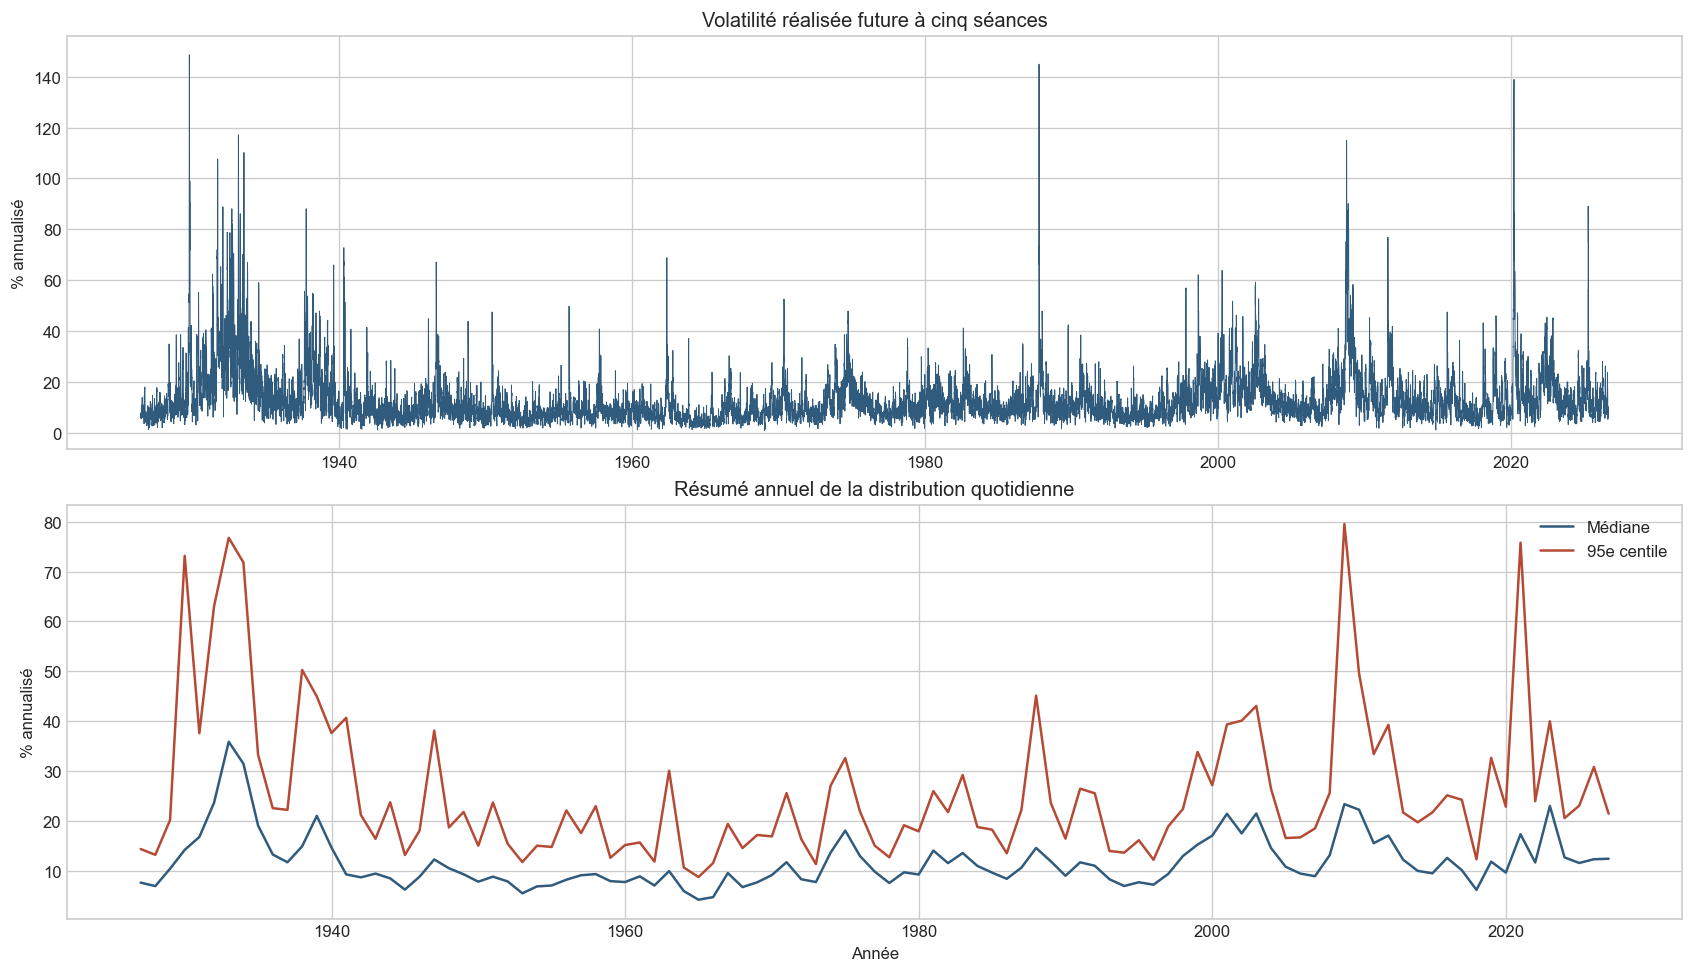

In [4]:
annual_summary = pd.DataFrame({
    'médiane annuelle': rv_5_pct.resample('YE').median(),
    '95e centile annuel': rv_5_pct.resample('YE').quantile(0.95),
})

fig, axes = plt.subplots(2, 1, figsize=(14, 8), constrained_layout=True)
axes[0].plot(rv_5_pct.index, rv_5_pct, color='#315b7d', linewidth=0.55)
axes[0].set(title='Volatilité réalisée future à cinq séances', ylabel='% annualisé')
axes[1].plot(annual_summary.index, annual_summary['médiane annuelle'], label='Médiane', color='#315b7d')
axes[1].plot(annual_summary.index, annual_summary['95e centile annuel'], label='95e centile', color='#b54a35')
axes[1].set(title='Résumé annuel de la distribution quotidienne', ylabel='% annualisé', xlabel='Année')
axes[1].legend()
plt.show()

## 4. Distribution et queue droite

Pour éviter qu'une poignée de valeurs n'écrase toute la résolution du graphique, l'histogramme principal est limité au 99,5e centile. Le nombre de valeurs exclues visuellement est annoncé ; elles restent présentes dans tous les calculs. Le second panneau utilise une échelle logarithmique et conserve toutes les observations.

Borne visuelle du panneau gauche : 69.34 %
Observations au-delà de cette borne, conservées dans les calculs : 132


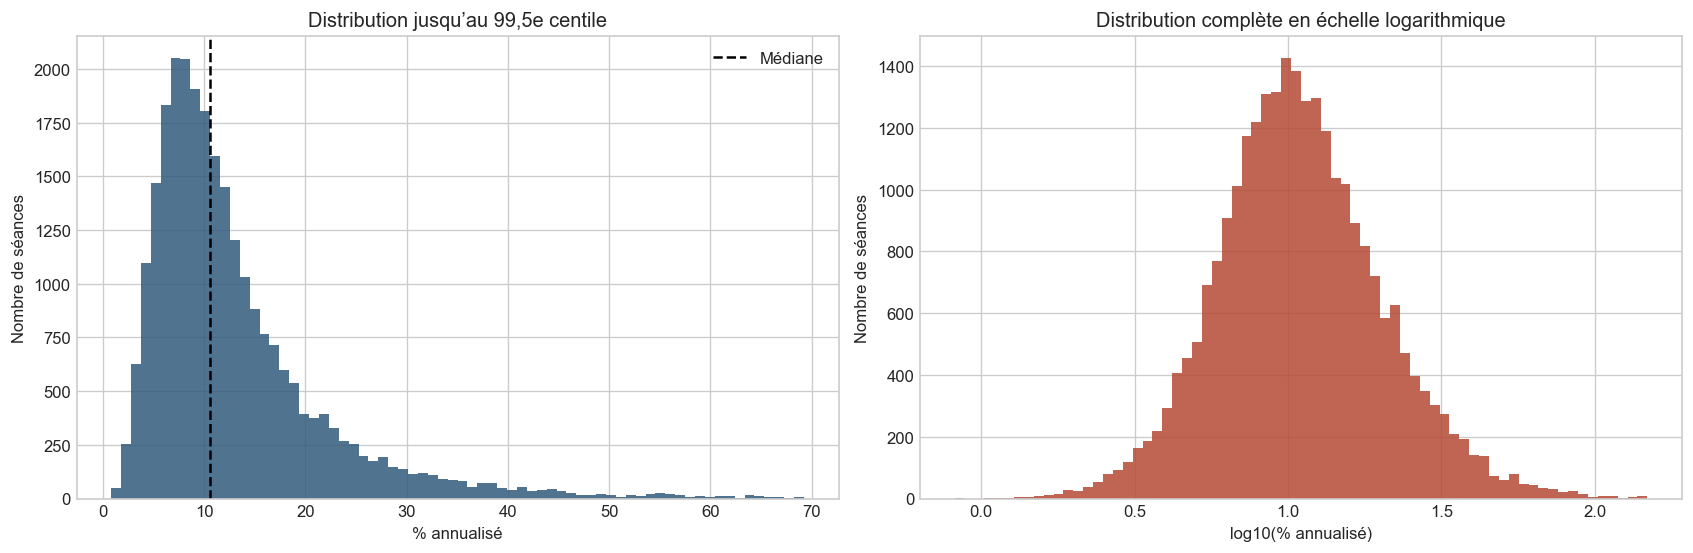

In [5]:
display_limit = rv_5_pct.quantile(0.995)
excluded_from_left_panel = int((rv_5_pct > display_limit).sum())

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), constrained_layout=True)
axes[0].hist(rv_5_pct[rv_5_pct <= display_limit], bins=70, color='#315b7d', alpha=0.85)
axes[0].axvline(rv_5_pct.median(), color='black', linestyle='--', label='Médiane')
axes[0].set(title='Distribution jusqu’au 99,5e centile', xlabel='% annualisé', ylabel='Nombre de séances')
axes[0].legend()
axes[1].hist(np.log10(rv_5_pct), bins=70, color='#b54a35', alpha=0.85)
axes[1].set(title='Distribution complète en échelle logarithmique', xlabel='log10(% annualisé)', ylabel='Nombre de séances')
plt.show()
print(f'Borne visuelle du panneau gauche : {display_limit:.2f} %')
print(f'Observations au-delà de cette borne, conservées dans les calculs : {excluded_from_left_panel}')

## 5. Périodes extrêmes

Une « période extrême » est définie ici, uniquement pour décrire la série, comme une suite de séances consécutives au-dessus de son 99e centile calculé sur tout l'échantillon. Ce seuil est descriptif et connu après coup : il ne constitue ni une catégorie économique, ni un signal utilisable en temps réel. Le chevauchement de la cible peut prolonger mécaniquement un épisode sur plusieurs lignes.

In [6]:
extreme_threshold = rv_5_pct.quantile(0.99)
is_extreme = rv_5_pct >= extreme_threshold
run_id = is_extreme.ne(is_extreme.shift(fill_value=False)).cumsum()
extreme_values = rv_5_pct[is_extreme]
episodes = []
for _, episode in extreme_values.groupby(run_id[is_extreme]):
    episodes.append({
        'début': episode.index.min().date().isoformat(),
        'fin': episode.index.max().date().isoformat(),
        'séances': len(episode),
        'date_du_pic': episode.idxmax().date().isoformat(),
        'maximum_pct': episode.max(),
    })
episodes = pd.DataFrame(episodes).sort_values('maximum_pct', ascending=False).reset_index(drop=True)
print(f'Seuil descriptif du 99e centile : {extreme_threshold:.2f} %')
print(f'Nombre de séances au-dessus du seuil : {int(is_extreme.sum())}')
print(f'Nombre de séquences contiguës : {len(episodes)}')
print('Dix séquences ayant les pics les plus élevés :')
print(episodes.head(10).round({'maximum_pct': 2}).to_string(index=False))

Seuil descriptif du 99e centile : 55.74 %
Nombre de séances au-dessus du seuil : 264
Nombre de séquences contiguës : 48
Dix séquences ayant les pics les plus élevés :
     début        fin  séances date_du_pic  maximum_pct
1929-10-22 1929-11-13       16  1929-10-26       148.60
1987-10-12 1987-10-23       10  1987-10-15       144.91
2020-03-02 2020-03-25       18  2020-03-11       138.91
1933-02-27 1933-03-03        5  1933-03-01       117.15
2008-09-30 2008-10-27       20  2008-10-08       114.94
1933-07-14 1933-07-22        8  1933-07-18       110.16
1931-09-30 1931-10-07        7  1931-10-02       107.64
2008-10-30 2008-11-28       21  2008-11-18        90.09
2025-03-28 2025-04-08        8  2025-04-02        89.01
1932-02-06 1932-02-11        5  1932-02-10        88.80


## 6. Persistance observée et persistance mécanique

Deux cibles voisines partagent quatre rendements sur cinq ; aux décalages 2, 3 et 4, elles en partagent respectivement trois, deux et un. Leur autocorrélation de court terme ne peut donc pas être interprétée comme une preuve pure de prévisibilité économique. Au décalage 5, les fenêtres ne partagent plus directement de rendement. Une autocorrélation encore positive au-delà est compatible avec une persistance du risque, sans établir sa cause ni garantir qu'elle soit exploitable hors échantillon.

    autocorrélation  rendements_partagés_directement
1             0.938                                4
2             0.876                                3
4             0.740                                1
5             0.668                                0
10            0.579                                0
22            0.476                                0
60            0.353                                0


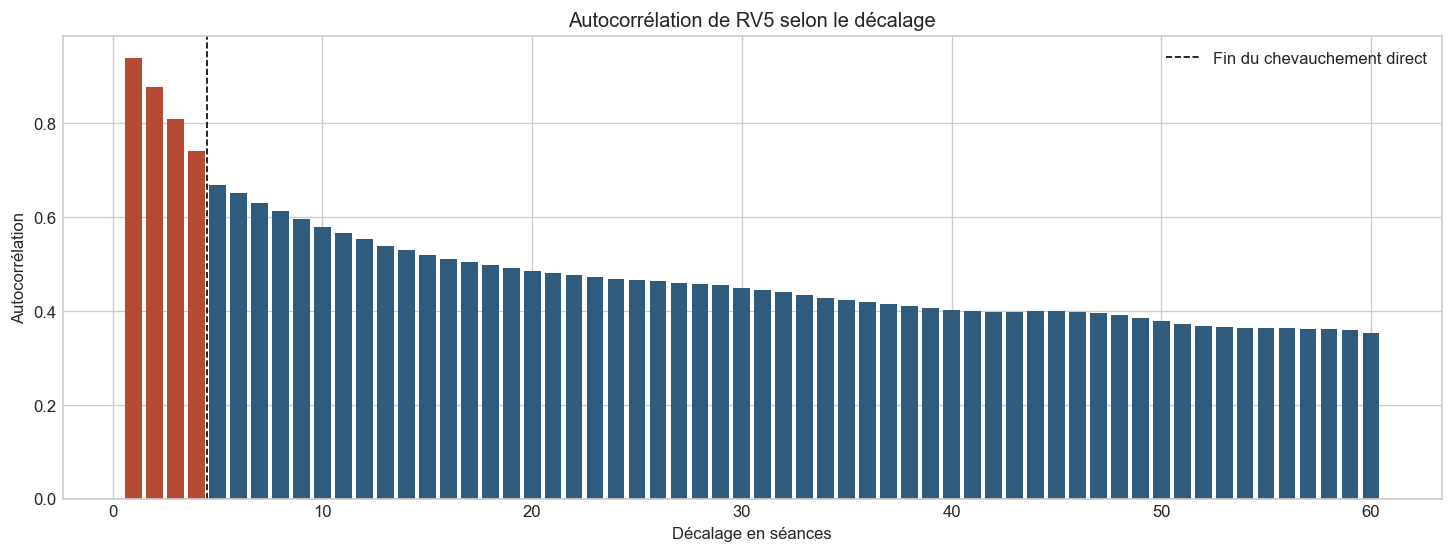

In [7]:
max_lag = 60
acf = pd.Series({lag: rv_5.autocorr(lag=lag) for lag in range(1, max_lag + 1)}, name='autocorrélation')
selected_lags = [1, 2, 4, 5, 10, 22, 60]
persistence_table = pd.DataFrame({
    'autocorrélation': acf.loc[selected_lags],
    'rendements_partagés_directement': [max(0, HORIZON - lag) for lag in selected_lags],
})

fig, ax = plt.subplots(figsize=(12, 4.5), constrained_layout=True)
ax.bar(acf.index, acf.values, color=np.where(acf.index < HORIZON, '#b54a35', '#315b7d'))
ax.axvline(HORIZON - 0.5, color='black', linestyle='--', linewidth=1, label='Fin du chevauchement direct')
ax.set(title='Autocorrélation de RV5 selon le décalage', xlabel='Décalage en séances', ylabel='Autocorrélation')
ax.legend()
plt.show()
print(persistence_table.round(3).to_string())

## 7. Limites de cette mesure du risque

1. **Proxy réalisé, non risque latent.** Cinq rendements constituent une mesure bruitée de la volatilité sous-jacente.
2. **Information connue après coup.** $RV_{5,t}$ décrit les cinq séances qui suivent $t$ ; ce n'est pas une prévision disponible à $t$.
3. **Chevauchement.** Les cibles adjacentes partagent jusqu'à quatre rendements, ce qui crée mécaniquement dépendance et grappes d'extrêmes.
4. **Données quotidiennes de clôture.** Les variations intrajournalières et certains mouvements entre observations ne sont pas directement mesurés.
5. **Annualisation conventionnelle.** Le facteur 252 facilite la lecture mais ne crée pas d'information et suppose une mise à l'échelle standard.
6. **Carrés des rendements.** La mesure ignore le signe : une hausse et une baisse de même amplitude contribuent pareillement, alors que leurs conséquences financières peuvent différer.
7. **Risque incomplet.** La volatilité ne décrit pas à elle seule les pertes extrêmes, la liquidité ou les conséquences pour une décision financière.
8. **Univers agrégé.** Le facteur de marché américain ne représente pas nécessairement le risque d'un actif ou d'un portefeuille particulier.
9. **Millésime courant.** La série téléchargée est la version aujourd'hui publiée ; elle ne reconstitue pas nécessairement tout ce qu'un chercheur aurait téléchargé à chaque date historique.

## Conclusion

La série est non négative, fortement dissymétrique, ponctuée d'épisodes extrêmes groupés et très autocorrélée. Une partie de la persistance de très court terme est certaine par construction à cause du chevauchement ; la persistance au-delà de quatre séances ne partage plus directement les mêmes rendements et mérite d'être distinguée de cet effet mécanique.

Cette description permet de comprendre la cible, mais ne démontre encore ni sa prévisibilité hors échantillon, ni la cause économique de ses variations, ni son utilité pour une décision financière.